In [1]:
import pandas as pd
import numpy as np
import config
import os

import kaplanmeier as km
from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from matplotlib import pyplot as plt
import seaborn as sns
from statsmodels.nonparametric.smoothers_lowess import lowess

from get_data import DataLoader


DataLoader = DataLoader(config.DATA_PATH, config.SEED)
df_smpl = DataLoader.assignment_prep()
df_smpl.head()

,id,status,time,hg,pap,cvd,stage,treat
336,338,1,14,17.500000,0.799927,yes,stage3,high-dose
267,269,1,40,13.199219,0.599976,no,stage3,high-dose
349,351,1,57,17.500000,0.699951,no,stage3,high-dose
437,439,0,70,13.599609,0.199982,no,stage3,high-dose
24,25,1,42,14.599609,3.899902,no,stage4,high-dose


In [4]:
# stage3 = df_smpl[df_smpl["stage"]=="stage3"]
# stage4   = df_smpl[df_smpl["stage"]=="stage4"]

# # Create figure
# plt.figure(figsize=(7,5))
# ax = plt.subplot(111)

# kmf = KaplanMeierFitter()

# # Stage 3
# kmf.fit(durations=stage3["time"],
#         event_observed=stage3["status"],
#         label="Stage 3")
# kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2)

# # Stage 4
# kmf.fit(durations=stage4["time"],
#         event_observed=stage4["status"],
#         label="Stage 4")
# kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2)

# # Labels and style
# plt.title("Kaplan–Meier Survival Curves by Stage", fontsize=12)
# plt.xlabel("Time (months)", fontsize=11)
# plt.ylabel("Survival Probability", fontsize=11)
# plt.grid(True, alpha=0.3)
# plt.legend(title="Cancer Stage")
# plt.tight_layout()
# plt.show()

In [5]:
# results = logrank_test(stage3['time'], 
#                        stage4['time'], 
#                        event_observed_A=stage3['status'], 
#                        event_observed_B=stage4['status'])
# print(results)

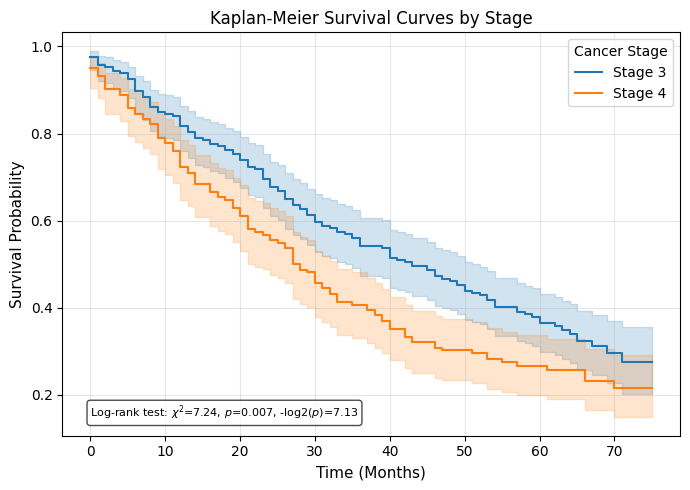

In [6]:
stage3 = df_smpl[df_smpl["stage"]=="stage3"]
stage4   = df_smpl[df_smpl["stage"]=="stage4"]

# Fit models
kmf = KaplanMeierFitter()

plt.figure(figsize=(7,5))
ax = plt.subplot(111)

# Stage 3
kmf.fit(stage3["time"], event_observed=stage3["status"], label="Stage 3")
kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2)

# Stage 4
kmf.fit(stage4["time"], event_observed=stage4["status"], label="Stage 4")
kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.2)

# Log-rank test
results = logrank_test(stage3["time"], stage4["time"],
                       event_observed_A=stage3["status"],
                       event_observed_B=stage4["status"])

p_value = results.p_value
chi2 = results.test_statistic
neg_log2_p = -np.log2(p_value)

# Annotate on plot (bottom right corner)
plt.text(
    x=0*max(stage3["time"].max(), stage4["time"].max()),
    y=0.15,
    s=fr"Log-rank test: $\chi^2$={chi2:.2f}, $p$={p_value:.3f}, -log2($p$)={neg_log2_p:.2f}",
    fontsize=8,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.7)
)

# Labels and style
plt.title("Kaplan-Meier Survival Curves by Stage", fontsize=12)
plt.xlabel("Time (Months)", fontsize=11)
plt.ylabel("Survival Probability", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(title="Cancer Stage")
plt.tight_layout()
plt.show()


In [8]:
# time_event = df_smpl['time']
# censoring  = df_smpl['status']
# y          = df_smpl['stage']

# # Compute Survival
# results = km.fit(time_event, censoring, y)

# # Plot
# km.plot(results, cmap='Set1', cii_lines='default', cii_alpha=0.05)

In [10]:
duration_col = "time"     # survival time column
event_col    = "status"   # 1 = event/death, 0 = censored

# list covariates of interest 
covariates   = ["hg", "pap", "cvd", "stage", "treat"]
categoricals = {"stage", "treat"} 
alpha = 0.05  # for 95% CI

id,status,time,hg,pap,cvd,stage,treat
1,0,72,13.79882813,0.299987793,no,stage3,low-dose
2,1,1,14.59960938,0.699951172,no,stage3,low-dose
3,1,40,13.3984375,0.299987793,yes,stage3,high-dose
4,1,20,17.59765625,0.899902344,yes,stage3,low-dose

# Model 1 - 5

In [11]:
rows = []
for i, var in enumerate(covariates, start=1):
    cph = CoxPHFitter()
    # Build a formula. If var is categorical, wrap in C()
    term = f"C({var})" if var in categoricals else var
    cph.fit(df_smpl[[duration_col, event_col, var]].dropna(),
            duration_col=duration_col, event_col=event_col,
            formula=term, robust=True)
    summ = cph.summary.copy()
    # lifelines returns one row per coefficient; for categorical, you'll get multiple levels
    summ["Model"] = f"Model {i}"
    summ["Covariate"] = summ.index  # keep full term names (incl. levels)
    summ["HR"] = np.exp(summ["coef"])
    summ["CI lower"] = np.exp(summ["coef lower 95%"])
    summ["CI upper"] = np.exp(summ["coef upper 95%"])
    summ = summ[["Model", "Covariate", "HR", "CI lower", "CI upper", "p"]]
    rows.append(summ)
out = pd.concat(rows, axis=0).reset_index(drop=True)

out.to_csv(os.path.join(config.OUTPUT_PATH, "cox_univariable_results.csv"), index=False)

# Model 6

In [15]:
# Build a multivariable formula combining C() for categorical vars
terms = [f"C({v})" if v in categoricals else v for v in covariates]
formula = " + ".join(terms)
cph6 = CoxPHFitter().fit(df_smpl[[duration_col, event_col] + covariates].dropna(),
        duration_col=duration_col, event_col=event_col,
        formula=formula, robust=True)
summ = cph6.summary.copy()
summ["Model"] = "Model 6 (multivariable)"
summ["Covariate"] = summ.index
summ["HR"] = np.exp(summ["coef"])
summ["CI lower"] = np.exp(summ["coef lower 95%"])
summ["CI upper"] = np.exp(summ["coef upper 95%"])
summ = summ[["Model", "Covariate", "HR", "CI lower", "CI upper", "p"]]

summ.to_csv(os.path.join(config.OUTPUT_PATH, "cox_multivariable_results.csv"), index=False)

In [16]:
cph6.print_summary()

<lifelines.CoxPHFitter: fitted with 376 total observations, 113 right-censored observations>
             duration col = 'time'
                event col = 'status'
          robust variance = True
      baseline estimation = breslow
   number of observations = 376
number of events observed = 263
   partial log-likelihood = -1401.45
         time fit was run = 2025-09-29 19:18:34 UTC

---
                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                             
hg                   -0.13      0.88      0.03           -0.20           -0.06                0.82                0.94
pap                  -0.00      1.00      0.00           -0.00            0.00                1.00                1.00
cvd[T.yes]            0.41      1.50      0.13            0.16            0.66                1.17                1.94
C(stage)[T.stage4]    0.28      1.32      0.13            0.01            0.54                1.01                1.72
C(treat)[T.low-dose]  0.19      1.21      0.15           -0.11            0.48                0.90                1.62
C(treat)[T.placebo]   0.10      1.10      0.16           -0.21            0.41                0.81                1.50

                      cmp to     z      p  -log2(p)
covariate                                          
hg                      0.00 -3.79 <0.005     12.72
pap                     0.00 -0.15   0.88      0.18
cvd[T.yes]              0.00  3.17 <0.005      9.35
C(stage)[T.stage4]      0.00  2.07   0.04      4.69
C(treat)[T.low-dose]    0.00  1.23   0.22      2.21
C(treat)[T.placebo]     0.00  0.61   0.54      0.89
---
Concordance = 0.61
Partial AIC = 2814.90
log-likelihood ratio test = 36.45 on 6 df
-log2(p) of ll-ratio test = 18.76

https://medium.com/@leushina.katya/how-to-use-the-cox-ph-model-in-survival-analysis-with-plots-and-python-code-88b83cbdad75
https://projector-video-pdf-converter.datacamp.com/25923/chapter2.pdf

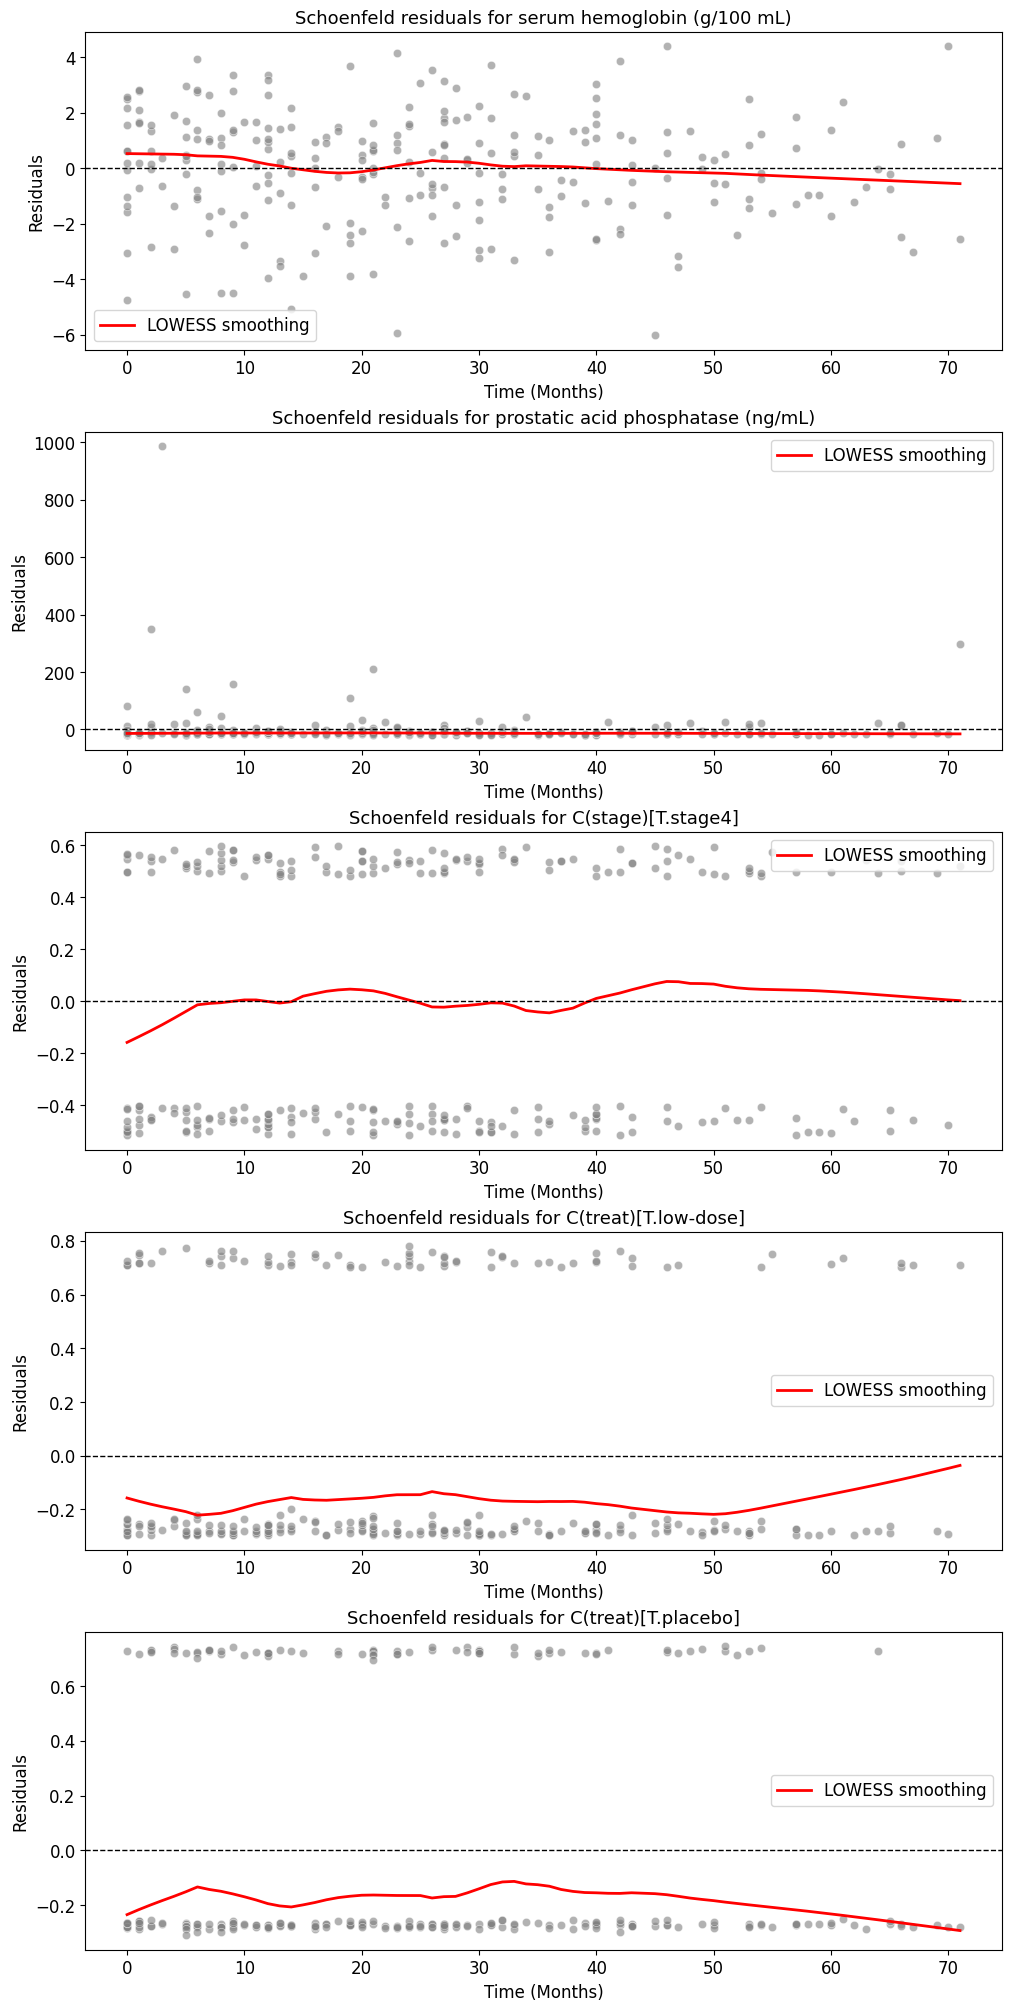

In [29]:

schoenfeld_resids = cph6.compute_residuals(df_smpl, kind='schoenfeld')

# Extract event times for uncensored observations only
event_times = df_smpl[df_smpl['status'] == 1]['time'].values

# Define covariates to plot
covariates_to_plot = ['hg']
covariates_to_plot = ["hg", "pap", "C(stage)[T.stage4]", "C(treat)[T.low-dose]", "C(treat)[T.placebo]"]

pretty = {
    "hg":  "serum hemoglobin (g/100 mL)",
    "pap": "prostatic acid phosphatase (ng/mL)"
}

# Set up plot
n = len(covariates_to_plot)
fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(10, 4 * n), constrained_layout=True)

# Ensure axes is iterable
if n == 1:
    axes = [axes]

# Plot residuals with LOWESS smoothing for each covariate
for i, covariate in enumerate(covariates_to_plot):
    y = schoenfeld_resids[covariate].values
    x = event_times

    # Compute LOWESS smoothing
    lowess_curve = lowess(y, x, frac=0.3)

    # Scatter plot of residuals
    sns.scatterplot(x=x, y=y, ax=axes[i], color='gray', alpha=0.6)

    # LOWESS smoothed line
    axes[i].plot(lowess_curve[:, 0], lowess_curve[:, 1], color='red', linewidth=2, label='LOWESS smoothing')

    # Zero reference line
    axes[i].axhline(0, linestyle='--', color='black', linewidth=1)

    # Set title and labels
    # axes[i].set_title(f"Schoenfeld residuals for serum hemoglobin (g/100 mL)", fontsize=14)
    axes[i].set_title(f"Schoenfeld residuals for {pretty.get(covariate, covariate)}", fontsize=13)
    axes[i].set_xlabel("Time (Months)", fontsize=12)
    axes[i].set_ylabel("Residuals", fontsize=12)
    axes[i].legend()

# Display the plot
plt.show()


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 376 total observations, 113 right-censored observations>
         test_name = proportional_hazard_test

---
                           test_statistic      p  -log2(p)
C(stage)[T.stage4]   km              0.94   0.33      1.59
                     rank            0.92   0.34      1.57
C(treat)[T.low-dose] km              7.76   0.01      7.55
                     rank            8.09 <0.005      7.81
C(treat)[T.placebo]  km              2.99   0.08      3.57
                     rank            3.00   0.08      3.58
cvd[T.yes]           km              0.30   0.58      0.78
                     rank            0.33   0.57      0.82
hg                   km              2.56   0.11      3.19
                     rank            2.65   0.10      3.27
pap                  km              0.49   0.48      1.05
                     rank            0.56   0.46      1.14



1. Variable 'C(treat)[T.low-dose]' failed the non-proportional test: p-value is 0.0045.

   Advice: with so few unique values (only 2), you can include `strata=['C(treat)[T.low-dose]',
...]` in the call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



[[<Axes: xlabel='rank-transformed time\n(p=0.1035)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1099)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.4552)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4824)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.5675)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5808)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.3370)'>,
  <Axes: xlabel='km-transformed time\n(p=0.3311)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0045)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0054)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0835)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0840)'>]]

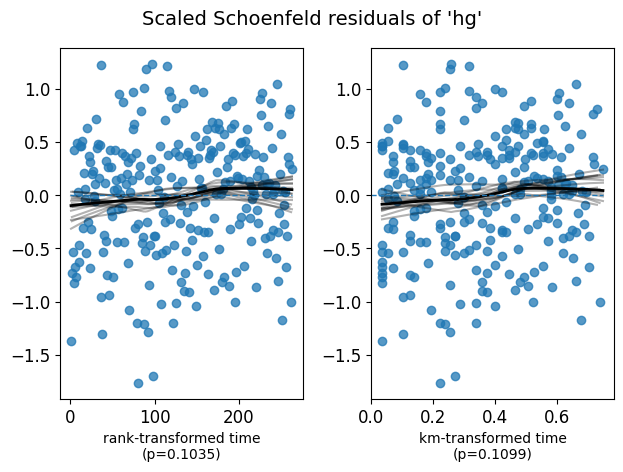

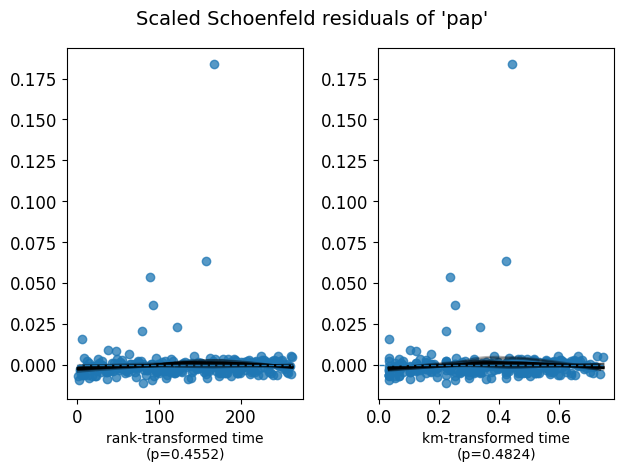

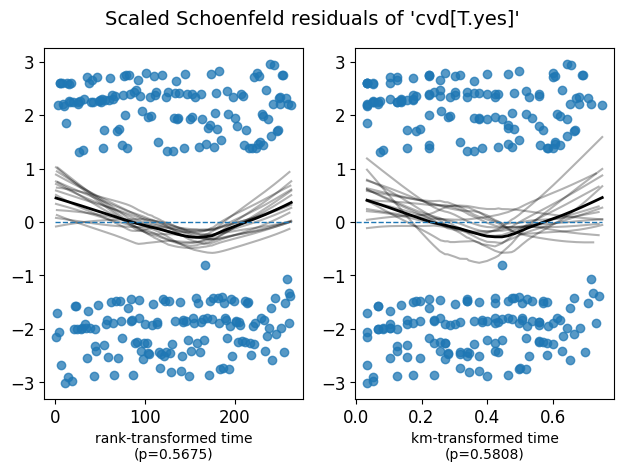

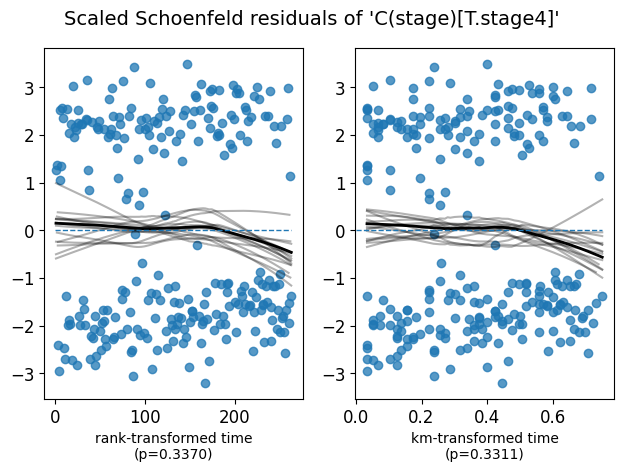

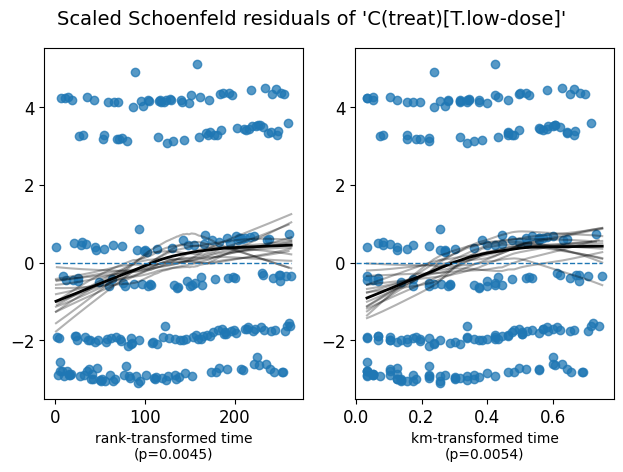

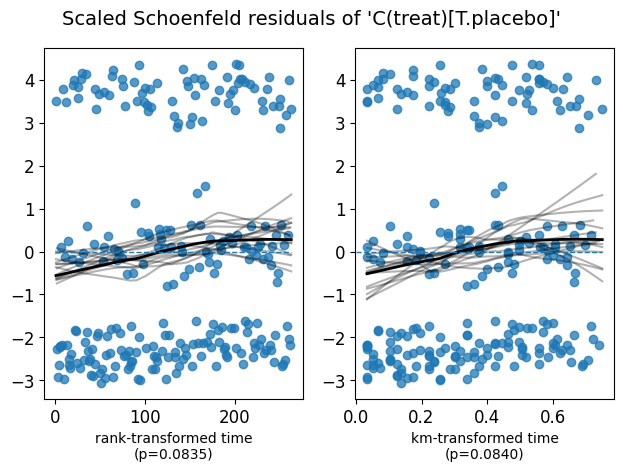

In [25]:
cph6.check_assumptions(df_smpl, show_plots=True, p_value_threshold=0.05)


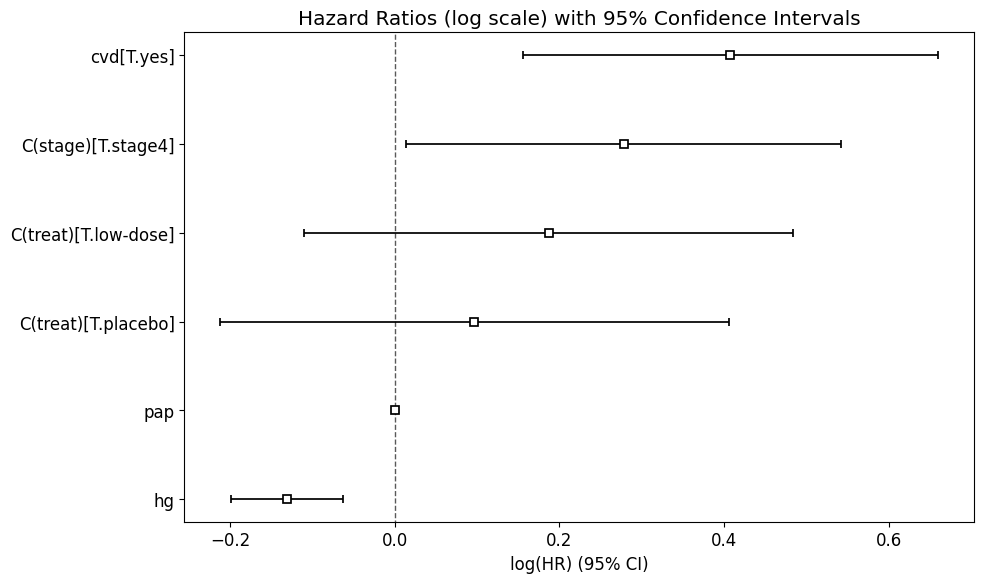

In [26]:
fig, ax = plt.subplots(figsize=(10, 6))
cph.plot(ax=ax)
plt.title("Hazard Ratios (log scale) with 95% Confidence Intervals")
plt.tight_layout()

plt.savefig("cox_ph_coefficient_plot.png")
plt.show()